# 06 - Multi-task learning: predicting the score and the class at the same time
Wine Quality dataset (red and white wines)

In the ML report regression and classification were two separate problems with two separate models.
With a neural network we can solve both with **one model**: a shared body (hard parameter sharing)
and two heads, one for the quality score (regression) and one for the Low / Medium / High class.

The total loss is

$$\mathcal{L} = \lambda_1 \, \mathcal{L}_{\text{MSE}} + \lambda_2 \, \mathcal{L}_{\text{CE}}$$

We compare:

1. Two single-task networks (one for each problem), as in notebook 01.
2. Multi-task network with equal weights ($\lambda_1 = \lambda_2 = 1$).
3. Multi-task network with weights learned during training (uncertainty weighting, Kendall et al. 2018).

All the networks have the same body (64-32, dropout 0.1). We use the stratified folds of the
classification problem for all the models, so all of them are evaluated on the same wines.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, f1_score, accuracy_score

from utils import *

set_style()
torch.set_num_threads(4)
np.random.seed(SEED)
torch.manual_seed(SEED)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

In [2]:
wine = load_wine()
X = wine[FEATURES].to_numpy()
y = wine["quality"].to_numpy().astype(float)
c = wine["class_id"].to_numpy()
HIDDEN, DROPOUT = (64, 32), 0.1

mse = nn.MSELoss()
ce = nn.CrossEntropyLoss()

## 1. Multi-task network

In [3]:
class MultiTaskMLP(nn.Module):
    def __init__(self, n_in, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.shared = MLP(n_in, hidden, 1, dropout).body   # shared layers
        self.reg_head = nn.Linear(hidden[-1], 1)            # quality score
        self.clf_head = nn.Linear(hidden[-1], 3)            # Low / Medium / High
        self.log_vars = nn.Parameter(torch.zeros(2))        # only used with uncertainty weighting

    def forward(self, x):
        h = self.shared(x)
        return self.reg_head(h).squeeze(1), self.clf_head(h)

mtl = MultiTaskMLP(X.shape[1])
print(mtl)
print("Multi-task parameters :", count_parameters(mtl) - 2)
print("Two single-task models:", count_parameters(MLP(X.shape[1], HIDDEN, 1)) + count_parameters(MLP(X.shape[1], HIDDEN, 3)))

MultiTaskMLP(
  (shared): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
  )
  (reg_head): Linear(in_features=32, out_features=1, bias=True)
  (clf_head): Linear(in_features=32, out_features=3, bias=True)
)
Multi-task parameters : 3044
Two single-task models: 5956


## 2. Losses

* Equal weights: $\mathcal{L}_{\text{MSE}} + \mathcal{L}_{\text{CE}}$.
* Uncertainty weighting: every task $i$ has a learnable parameter $s_i = \log \sigma_i^2$ and the
  loss is $\sum_i e^{-s_i} \mathcal{L}_i + s_i$. If a task is noisy, the network can make its
  weight $e^{-s_i}$ smaller, but the $+ s_i$ term stops it from making all the weights zero.

For early stopping we always use the unweighted sum on the validation set, so all the multi-task
models are stopped with the same rule.

In [4]:
def reg_loss(out, yr):
    return mse(out.squeeze(1), yr)

def clf_loss(out, yc):
    return ce(out, yc)

def mtl_equal(out, yr, yc):
    return mse(out[0], yr) + ce(out[1], yc)

def mtl_uncertainty(model):
    def loss(out, yr, yc):
        s = model.log_vars
        return torch.exp(-s[0]) * mse(out[0], yr) + s[0] + torch.exp(-s[1]) * ce(out[1], yc) + s[1]
    return loss

def to_class(score):
    # thresholds of the classes: Low <= 5, Medium = 6, High >= 7
    return np.digitize(score, [5.5, 6.5])

## 3. Cross-validation

In [5]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows, weights = [], []

for fold, (train_idx, test_idx) in enumerate(outer.split(X, c), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED, stratify=c[train_idx])
    scaler = StandardScaler().fit(X[tr])
    y_mean, y_std = y[tr].mean(), y[tr].std()
    Xtr, Xval, Xte = (to_tensor(scaler.transform(X[i])) for i in (tr, val, test_idx))
    ytr, yval = (to_tensor((y[i] - y_mean) / y_std) for i in (tr, val))
    ctr, cval = (torch.tensor(c[i], dtype=torch.long) for i in (tr, val))
    y_te, c_te = y[test_idx], c[test_idx]

    def scores(name, score_pred, class_pred):
        rows.append({"fold": fold, "model": name,
                     "RMSE": rmse(y_te, score_pred) if score_pred is not None else np.nan,
                     "R2": r2_score(y_te, score_pred) if score_pred is not None else np.nan,
                     "Macro F1": f1_score(c_te, class_pred, average="macro"),
                     "Accuracy": accuracy_score(c_te, class_pred)})

    # single-task regression
    torch.manual_seed(SEED)
    m_reg = MLP(X.shape[1], HIDDEN, 1, DROPOUT)
    train_model(m_reg, Xtr, (ytr,), Xval, (yval,), reg_loss)
    with torch.no_grad():
        score_reg = m_reg.eval()(Xte).squeeze(1).numpy() * y_std + y_mean

    # single-task classification
    torch.manual_seed(SEED)
    m_clf = MLP(X.shape[1], HIDDEN, 3, DROPOUT)
    train_model(m_clf, Xtr, (ctr,), Xval, (cval,), clf_loss)
    with torch.no_grad():
        class_clf = m_clf.eval()(Xte).argmax(1).numpy()

    rows.append({"fold": fold, "model": "Single-task (two networks)", "RMSE": rmse(y_te, score_reg),
                 "R2": r2_score(y_te, score_reg), "Macro F1": f1_score(c_te, class_clf, average="macro"),
                 "Accuracy": accuracy_score(c_te, class_clf)})
    scores("Regression network + thresholds", None, to_class(score_reg))

    # multi-task networks
    for name in ["Multi-task (equal weights)", "Multi-task (uncertainty weights)"]:
        torch.manual_seed(SEED)
        m = MultiTaskMLP(X.shape[1])
        loss = mtl_equal if "equal" in name else mtl_uncertainty(m)
        train_model(m, Xtr, (ytr, ctr), Xval, (yval, cval), loss, val_loss_fn=mtl_equal)
        with torch.no_grad():
            out_r, out_c = m.eval()(Xte)
        scores(name, out_r.numpy() * y_std + y_mean, out_c.argmax(1).numpy())
        if "uncertainty" in name:
            w = torch.exp(-m.log_vars).detach().numpy()
            weights.append({"fold": fold, "weight regression": w[0], "weight classification": w[1]})
    print(f"fold {fold} done")

folds = pd.DataFrame(rows)
summary = folds.groupby("model", sort=False).agg(["mean", "std"])[["RMSE", "R2", "Macro F1", "Accuracy"]]
folds.to_csv(RES_DIR / "mtl_folds.csv", index=False)
summary.to_csv(RES_DIR / "mtl_summary.csv")
display(summary.round(3))
display(pd.DataFrame(weights).round(2))

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


RMSE            R2        Macro F1         \
                                   mean    std   mean    std     mean    std   
model                                                                          
Single-task (two networks)        0.693  0.014  0.379  0.007    0.585  0.012   
Regression network + thresholds     NaN    NaN    NaN    NaN    0.581  0.008   
Multi-task (equal weights)        0.693  0.012  0.380  0.007    0.581  0.007   
Multi-task (uncertainty weights)  0.692  0.012  0.380  0.009    0.582  0.006   

                                 Accuracy         
                                     mean    std  
model                                             
Single-task (two networks)          0.609  0.012  
Regression network + thresholds     0.607  0.006  
Multi-task (equal weights)          0.604  0.004  
Multi-task (uncertainty weights)    0.607  0.003

,fold,weight regression,weight classification
0,1,1.74,1.31
1,2,1.72,1.31
2,3,1.76,1.33
3,4,1.69,1.28
4,5,1.75,1.31


## 4. Comparison

Figure saved -> ../results/figures/mtl_comparison.png


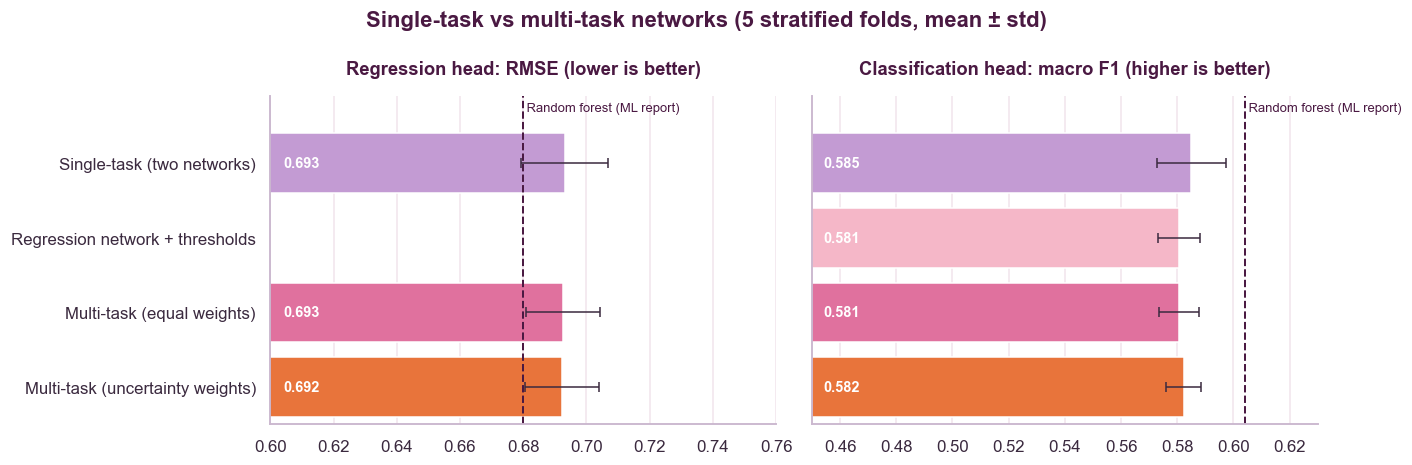

In [6]:
mean = folds.groupby("model", sort=False).mean(numeric_only=True)
std = folds.groupby("model", sort=False).std(numeric_only=True)
colors = [LILAC, ROSE, PINK, ORANGE]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, col, title, lim, ref in [(axes[0], "RMSE", "Regression head: RMSE (lower is better)", (0.6, 0.76), 0.680),
                                 (axes[1], "Macro F1", "Classification head: macro F1 (higher is better)", (0.45, 0.63), 0.604)]:
    ax.barh(mean.index, mean[col], xerr=std[col], color=colors, edgecolor="white",
            error_kw=dict(ecolor=INK, lw=1, capsize=3))
    for i, v in enumerate(mean[col]):
        if not np.isnan(v):
            ax.text(lim[0] + 0.004, i, f"{v:.3f}", va="center", fontsize=9.5, color="white", weight="bold")
    ax.axvline(ref, color=PLUM, ls="--", lw=1.3)
    ax.text(ref, -0.65, " Random forest (ML report)", color=PLUM, fontsize=8.5, va="bottom")
    ax.set_xlim(*lim)
    ax.set_ylim(len(mean) - 0.5, -0.9)
    ax.set_title(title, pad=14)
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.suptitle("Single-task vs multi-task networks (5 stratified folds, mean ± std)", color=PLUM, fontweight="semibold")
fig.tight_layout()
save(fig, "mtl_comparison.png")
plt.show()

## 5. A different auxiliary task: the wine type

The two tasks above contain the same information. Now we try an auxiliary task that is really
different: predicting if the wine is red or white (binary cross-entropy) while predicting the
score. To make this task useful, `is_red` is **removed from the inputs**, so the network has to
learn the wine type from the physicochemical measurements. We compare:

* Single-task regression with `is_red` as input (the network used until now).
* Single-task regression without `is_red`.
* Multi-task network without `is_red`: regression head + wine type head, equal weights.

Early stopping uses only the regression loss, because the score is the task we care about.

In [7]:
PHYS = [f for f in FEATURES if f != "is_red"]
X11 = wine[PHYS].to_numpy()
t = wine["is_red"].to_numpy().astype(float)
bce = nn.BCEWithLogitsLoss()

class TypeMultiTaskMLP(nn.Module):
    def __init__(self, n_in, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.shared = MLP(n_in, hidden, 1, dropout).body
        self.reg_head = nn.Linear(hidden[-1], 1)     # quality score
        self.type_head = nn.Linear(hidden[-1], 1)    # red (1) or white (0)

    def forward(self, x):
        h = self.shared(x)
        return self.reg_head(h).squeeze(1), self.type_head(h).squeeze(1)

def score_and_type(out, yr, yt):
    return mse(out[0], yr) + bce(out[1], yt)

def score_only(out, yr, yt):
    return mse(out[0], yr)

rows2 = []
for fold, (train_idx, test_idx) in enumerate(outer.split(X, c), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED, stratify=c[train_idx])
    y_mean, y_std = y[tr].mean(), y[tr].std()
    ytr, yval = (to_tensor((y[i] - y_mean) / y_std) for i in (tr, val))
    ttr, tval = to_tensor(t[tr]), to_tensor(t[val])

    for name, Xin in [("Single-task, with is_red", X), ("Single-task, without is_red", X11)]:
        sc = StandardScaler().fit(Xin[tr])
        Xtr, Xval, Xte = (to_tensor(sc.transform(Xin[i])) for i in (tr, val, test_idx))
        torch.manual_seed(SEED)
        m = MLP(Xin.shape[1], HIDDEN, 1, DROPOUT)
        train_model(m, Xtr, (ytr,), Xval, (yval,), reg_loss)
        with torch.no_grad():
            p = m.eval()(Xte).squeeze(1).numpy() * y_std + y_mean
        rows2.append({"fold": fold, "model": name, "RMSE": rmse(y[test_idx], p), "Type accuracy": np.nan})

    sc = StandardScaler().fit(X11[tr])
    Xtr, Xval, Xte = (to_tensor(sc.transform(X11[i])) for i in (tr, val, test_idx))
    torch.manual_seed(SEED)
    m = TypeMultiTaskMLP(X11.shape[1])
    train_model(m, Xtr, (ytr, ttr), Xval, (yval, tval), score_and_type, val_loss_fn=score_only)
    with torch.no_grad():
        out_r, out_t = m.eval()(Xte)
    rows2.append({"fold": fold, "model": "Multi-task (score + wine type), without is_red",
                  "RMSE": rmse(y[test_idx], out_r.numpy() * y_std + y_mean),
                  "Type accuracy": accuracy_score(t[test_idx], (out_t.numpy() > 0).astype(float))})
    print(f"fold {fold} done")

type_res = pd.DataFrame(rows2)
type_res.to_csv(RES_DIR / "mtl_wine_type_folds.csv", index=False)
type_summary = type_res.groupby("model", sort=False)[["RMSE", "Type accuracy"]].agg(["mean", "std"])
type_summary.to_csv(RES_DIR / "mtl_wine_type_summary.csv")
type_summary.round(3)

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


RMSE        Type accuracy  \
                                                 mean    std          mean   
model                                                                        
Single-task, with is_red                        0.693  0.014           NaN   
Single-task, without is_red                     0.697  0.012           NaN   
Multi-task (score + wine type), without is_red  0.691  0.009         0.995   

                                                       
                                                  std  
model                                                  
Single-task, with is_red                          NaN  
Single-task, without is_red                       NaN  
Multi-task (score + wine type), without is_red  0.001

## Summary

* One multi-task network gives practically the same results as two single-task networks, with
  about half of the parameters (3,044 instead of 5,956). There is no clear improvement, because both
  tasks use exactly the same information (the class is just the score cut in three intervals).
* The learned (uncertainty) weights give more importance to the regression task (about 1.7 vs 1.3).
* Cutting the prediction of the regression network with the class thresholds gives almost the same
  macro F1 as the classification network.
* With the wine type as auxiliary task (and without `is_red` in the inputs), the multi-task
  network predicts the type almost perfectly (99.5% accuracy) and gets an RMSE of 0.691, slightly
  better than the single-task network without `is_red` (0.697) and even than the one with it
  (0.693). The differences are smaller than the standard deviation between folds, so the effect is
  small, but here the auxiliary task gives information that is not in the main target.
